# Lab 07: Xarray + Dask — chunking and lazy computation

Last week we put observations into **NetCDF, Zarr and Xarray** and built a labelled
spatiotemporal Dataset. But what happens when that Dataset **outgrows one machine's
memory**? Ten years of global satellite temperature fields is several TB — load it whole
into an `np.array` and the process dies on the spot.

Today's answer is **Dask**. It cuts a large array into small **chunks** and, instead of
executing a computation immediately, **defers it (lazily)** as a **task graph** — a blueprint
recording what to do in what order. Only when you call `.compute()` does dask pull the chunks
out **one at a time**, compute them and combine the results — finishing a TB-scale aggregation
without ever holding the whole thing in memory. Xarray wraps these dask arrays with coordinates
and dimension names, so code like the `.mean("time")` we wrote in Week 6 runs **unchanged** at
large scale.

## Learning Objectives

By the end of this lab you will be able to:

- Understand a dask array's **chunks, task graph and `.compute()`**, and make a large xarray
  Dataset **dask-backed** with `chunks=` (or `.chunk()`).
- Distinguish **lazy from eager**: prove with a counter that `.data` is a dask array, how many
  chunks and tasks there are, and that **no computation happens** before `.compute()`.
- See the trade-off of **chunking strategy** (too small raises scheduling overhead, too large
  raises memory) on a chunk-count vs task-count curve, and re-divide chunks with `rechunk`.
- Complete the time mean of data **larger than the memory budget** with **chunkwise
  out-of-core** execution, and confirm the result is `np.allclose` to the eager numpy
  computation.
- Compare the timing of the single-machine **threaded and synchronous schedulers** and watch
  execution with a `ProgressBar`.
- Apply **custom chunkwise operations** (standardised anomalies, rolling means) with
  `xr.apply_ufunc`/`map_blocks`, and see numerically **when not to use dask** (small-data
  overhead).


In [27]:

import os, sys, time, math, tempfile

import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

import dask
import dask.array as da
import xarray as xr
from dask.diagnostics import ProgressBar

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
rng = np.random.default_rng(0)          # reproducibility: fixed seed

# Today's outputs stay inside this temporary directory (the course repo is untouched).
WORK = tempfile.mkdtemp(prefix="course410_wk07_")
print("working directory:", WORK)
print("python           :", sys.version.split()[0])
print("numpy            :", np.__version__)
print("dask             :", dask.__version__)
print("xarray           :", xr.__version__)


working directory: /var/folders/hh/w5xjnck119d_h0x6gxztgrwr0000gn/T/course410_wk07_oda_rarv
python           : 3.11.0
numpy            : 2.3.3
dask             : 2025.9.1
xarray           : 2025.9.1


---
## 1. Dask array basics — chunks · task graph · `.compute()`

`dask.array` has **the same interface** as a numpy array (`.mean()`, `+`, `np.exp(...)`), but
its insides are entirely different. It divides one large array into a grid of small numpy
blocks called **chunks**, and when you call an operation it **does not compute immediately**.
Instead it stacks up a **task graph**: "this operation on this chunk, then combine with that
chunk...". The actual computation runs chunk by chunk the moment you call `.compute()`.

That lazy evaluation is the key to large data: even with the whole array absent from memory,
dask can create, process and discard **only the chunks it needs**, one at a time. Let us get a
feel for `chunks`, block counts and `.compute()` on a very small example first.


In [28]:

# A 12x12 array in 4x4 chunks -> a grid of 3x3 = 9 blocks.
x = da.arange(144, chunks=16).reshape(12, 12).rechunk((4, 4))
print("dask array x:", x)
print("shape        :", x.shape)
print("chunks       :", x.chunks, "  (how each axis is divided)")
print("block grid   :", x.numblocks, " -> total chunks, npartitions =", x.npartitions)
print("dtype        :", x.dtype, "| logical size nbytes =", x.nbytes, "bytes")
print()
print("type(x)      :", type(x).__name__, "-- not numpy, but an 'as yet uncomputed' array")


dask array x: dask.array<rechunk-merge, shape=(12, 12), dtype=int64, chunksize=(4, 4), chunktype=numpy.ndarray>
shape        : (12, 12)
chunks       : ((4, 4, 4), (4, 4, 4))   (how each axis is divided)
block grid   : (3, 3)  -> total chunks, npartitions = 9
dtype        : int64 | logical size nbytes = 1152 bytes

type(x)      : Array -- not numpy, but an 'as yet uncomputed' array


In [3]:

# .mean() is not a 'computation' -- it only lays one more layer on the blueprint (the task graph).
red = x.mean()
print("x.mean() itself:", red, " <- not a value but a deferred dask scalar")
print("nodes in the task graph:", len(red.__dask_graph__()), "tasks")
print()

# Only .compute() runs it chunk by chunk and produces a numpy value.
val = red.compute()
print("red.compute() =", val, " (type:", type(val).__name__, ")")
print("numpy check   =", np.arange(144).reshape(12, 12).mean())
assert np.isclose(val, np.arange(144).reshape(12, 12).mean())
print("-> the dask result matches the eager numpy computation exactly.")


x.mean() itself: dask.array<mean_agg-aggregate, shape=(), dtype=float64, chunksize=(), chunktype=numpy.ndarray>  <- not a value but a deferred dask scalar
nodes in the task graph: 110 tasks

red.compute() = 71.5  (type: float64 )
numpy check   = 71.5
-> the dask result matches the eager numpy computation exactly.


the 12x12 array was divided into 9 numpy blocks of 4x4.


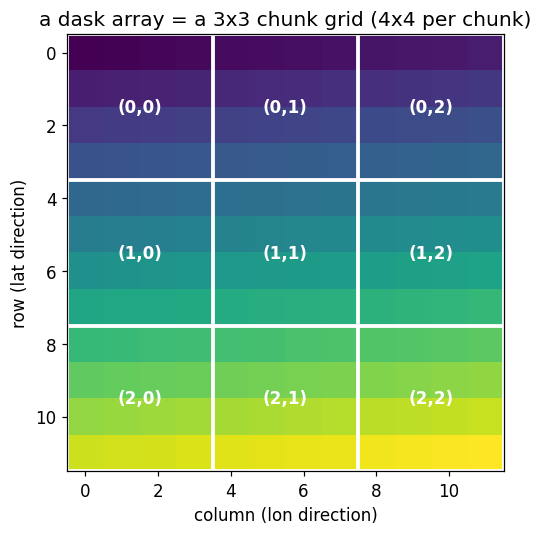

In [4]:

# The chunk grid as a figure -- a big array divided into 'tiles' of numpy blocks.
data = x.compute()
ci, cj = x.chunks[0], x.chunks[1]          # the chunk boundary lengths per axis

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.imshow(data, cmap="viridis", origin="upper")
# draw the chunk boundaries (thick)
bx = np.cumsum((0,) + cj)                   # vertical boundary positions
by = np.cumsum((0,) + ci)                   # horizontal boundary positions
for b in bx:
    ax.axvline(b - 0.5, color="w", lw=2.5)
for b in by:
    ax.axhline(b - 0.5, color="w", lw=2.5)
# label each chunk with its block index
for ii in range(len(ci)):
    for jj in range(len(cj)):
        cy = by[ii] + ci[ii] / 2 - 0.5
        cx = bx[jj] + cj[jj] / 2 - 0.5
        ax.text(cx, cy, f"({ii},{jj})", color="w", ha="center", va="center",
                fontsize=11, fontweight="bold")
ax.set_title(f"a dask array = a {x.numblocks[0]}x{x.numblocks[1]} chunk grid "
             f"({ci[0]}x{cj[0]} per chunk)")
ax.set_xlabel("column (lon direction)"); ax.set_ylabel("row (lat direction)")
plt.tight_layout()
print(f"the 12x12 array was divided into {x.npartitions} numpy blocks of 4x4.")


In [29]:

# Open the task graph directly and you see the 'blueprint' really is a dictionary.
tiny = da.arange(8, chunks=4)                 # 2 chunks
g = dict(tiny.sum().__dask_graph__())
print(f"sum() task graph: {len(g)} nodes")
for k in list(g)[:6]:
    print("  key:", k)
print("-> each key is one task, pointing at 'which operation on which chunk'.")


sum() task graph: 5 nodes
  key: ('arange-c5e216bdb84530596b615bcbf76c3102', 0)
  key: ('arange-c5e216bdb84530596b615bcbf76c3102', 1)
  key: ('sum-acf70b0b928919567006766ee0c3e379', 0)
  key: ('sum-acf70b0b928919567006766ee0c3e379', 1)
  key: ('sum-aggregate-bcd71f88065d5fd235ec8f4b5b524286',)
-> each key is one task, pointing at 'which operation on which chunk'.


If you want just one chunk you can address an **individual block** with `.blocks[i, j]`, and
slicing (`x[2:6, :]`) is equally **lazy** — only the chunks that are needed take part in the
computation.


In [6]:

# Block access and slicing are both lazy -- only the chunks needed get computed.
blk = x.blocks[1, 2]                          # one (1,2) block = a 4x4 numpy array
print("x.blocks[1,2] :", blk, "->", type(blk).__name__, "(still lazy)")
print("its values:\n", blk.compute())

sub = x[2:6, 0:4]                             # slicing is lazy too
print("\nx[2:6, 0:4] is lazy:", type(sub).__name__,
      "| the chunk grid this slice touches:", sub.numblocks)
print("-> block access and slicing both involve only the chunks that are needed (partial loading).")


x.blocks[1,2] : dask.array<blocks, shape=(4, 4), dtype=int64, chunksize=(4, 4), chunktype=numpy.ndarray> -> Array (still lazy)
its values:
 [[56 57 58 59]
 [68 69 70 71]
 [80 81 82 83]
 [92 93 94 95]]

x[2:6, 0:4] is lazy: Array | the chunk grid this slice touches: (2, 1)
-> block access and slicing both involve only the chunks that are needed (partial loading).


> **Observe:** a dask array has **the same API** as numpy, yet `x.mean()` returned not a
> value but a **task graph** (several tasks). Only `.compute()` executed it chunk by chunk and
> produced a numpy value, which matched the eager computation exactly. Individual block access
> (`.blocks`) and slicing are lazy too, pulling out only the chunks required. As the figure
> shows, a large array is divided into **chunk tiles**, and dask simply processes those tiles
> one at a time — that is the principle behind handling arrays larger than memory. Let us now
> put such a dask array into an **xarray Dataset**.


---
## 2. Making a large xarray Dataset dask-backed — and proving it is lazy

Now we build a Week 6-style **spatiotemporal temperature Dataset**, but fill it with dask
arrays. A `(time=240, lat=200, lon=200)` float32 array is about 38 MB, which is safe for this
lab, but scale `time` up to 100,000 with **the same code** and it becomes 16 TB — at which point
numpy cannot load it whole. So we build the habit of **generating it lazily, chunk by chunk**,
from the very start.

The key tool is `da.map_blocks(func, template)`: dask calls `func` as it creates each chunk and
tells it, through `block_info`, "where in the whole array this chunk sits". We use that position
to compute **just this chunk's worth of the temperature field** (the Week 4 structure: an
afternoon-peaking diurnal cycle plus cooler-to-the-north). Because we never build the whole
thing at once, this is **genuinely out-of-core**.


In [7]:

# The (global) coordinate axes -- a grid around the Korean peninsula, ten days of hourly data.
T, H, W = 240, 200, 200                       # time, lat, lon
LAT = np.linspace(34.0, 38.0, H).astype("f8")
LON = np.linspace(126.0, 130.0, W).astype("f8")
TIME = pd.date_range("2025-08-01", periods=T, freq="h")

GEN_CALLS = {"n": 0}                           # a chunk-generation call counter (to prove laziness)

def gen_temp_block(block, block_info=None):
    # Dask calls this function as it computes each chunk. It receives the position through
    # block_info and returns only 'this chunk's worth' of the temperature field (never the whole array).
    if block_info is None:                      # a guard for meta inference (not a real chunk)
        return block.astype("f4")
    (t0, t1), (y0, y1), (x0, x1) = block_info[0]["array-location"]
    GEN_CALLS["n"] += 1                         # this chunk was 'actually' generated
    hour = np.arange(t0, t1) % 24
    diurnal = 4.0 * np.sin(2 * np.pi * (hour - 9) / 24.0)   # afternoon peak (~15:00)
    latg = -1.8 * (LAT[y0:y1] - 36.0)                        # cooler further north
    long_ = 0.4 * (LON[x0:x1] - 128.0)                       # slightly warmer to the east
    field = 27.0 + diurnal[:, None, None] + latg[None, :, None] + long_[None, None, :]
    return field.astype("f4")

def make_temp_dask(chunks):
    # Build a lazy temperature-field dask array with the given chunks (values are created at compute time).
    template = da.zeros((T, H, W), chunks=chunks, dtype="f4")
    return da.map_blocks(gen_temp_block, template, dtype="f4",
                         meta=np.array((), dtype="f4"))

CHUNKS = (24, 50, 50)                           # time 24, space 50x50
temp = make_temp_dask(CHUNKS)
print("temp (a lazy dask array):", temp)
print("shape / chunk grid       :", temp.shape, "/", temp.numblocks,
      "=", temp.npartitions, "chunks")
print(f"total logical size       : {temp.nbytes/1e6:.1f} MB "
      f"(with time=100,000 it would be {temp.nbytes/1e6*(100000/T)/1e6:.1f} TB)")


temp (a lazy dask array): dask.array<gen_temp_block, shape=(240, 200, 200), dtype=float32, chunksize=(24, 50, 50), chunktype=numpy.ndarray>
shape / chunk grid       : (240, 200, 200) / (10, 4, 4) = 160 chunks
total logical size       : 38.4 MB (with time=100,000 it would be 0.0 TB)


In [8]:

# Wrapping it in xarray -- coordinates and dimension names get attached, but the data is still dask (lazy).
ds = xr.Dataset(
    {"temp": (("time", "lat", "lon"), temp)},
    coords={"time": TIME, "lat": LAT, "lon": LON},
    attrs={"note": "synthetic spatiotemporal temperature field (dask-backed)"},
)
print(ds)
print()
print("type of ds.temp.data :", type(ds.temp.data).__name__, "<- not numpy, dask!")
print("ds.temp.chunks       :", ds.temp.chunks[0][:3], "... (the chunk lengths along time)")
print("logical nbytes       :", f"{ds.temp.nbytes/1e6:.1f} MB (not in memory yet)")


<xarray.Dataset> Size: 38MB
Dimensions:  (time: 240, lat: 200, lon: 200)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2025-08-01 ... 2025-08-10T23:00:00
  * lat      (lat) float64 2kB 34.0 34.02 34.04 34.06 ... 37.94 37.96 37.98 38.0
  * lon      (lon) float64 2kB 126.0 126.0 126.0 126.1 ... 130.0 130.0 130.0
Data variables:
    temp     (time, lat, lon) float32 38MB dask.array<chunksize=(24, 50, 50), meta=np.ndarray>
Attributes:
    note:     synthetic spatiotemporal temperature field (dask-backed)

type of ds.temp.data : Array <- not numpy, dask!
ds.temp.chunks       : (24, 24, 24) ... (the chunk lengths along time)
logical nbytes       : 38.4 MB (not in memory yet)


If you already have a DataArray **loaded into memory as numpy**, as in Week 6, you can turn
it dask-backed afterwards with `.chunk()` (though since it is already in memory there is no
out-of-core benefit, only **parallelism**). For genuinely large data the proper approach is to
open it as dask **from the start**, as in `open_mfdataset(..., chunks=...)`.


In [9]:

# Path (b): converting a numpy-backed DataArray to dask-backed with .chunk().
_hour = np.arange(T) % 24
_field = (27.0 + 4.0 * np.sin(2 * np.pi * (_hour - 9) / 24.0)[:, None, None]
          - 1.8 * (LAT - 36.0)[None, :, None]
          + 0.4 * (LON - 128.0)[None, None, :]).astype("f4")   # numpy, loaded into memory
eager_da = xr.DataArray(_field, dims=("time", "lat", "lon"),
                        coords={"time": TIME, "lat": LAT, "lon": LON})
print("type of .data before:", type(eager_da.data).__name__, "(numpy, already in memory)")
chunked_da = eager_da.chunk({"time": 60, "lat": 100, "lon": 100})
print("type of .data after :", type(chunked_da.data).__name__,
      "| chunks:", chunked_da.data.npartitions)
print(".compute() and .load(): both realise the values, but .load() turns the xarray object")
print("  itself numpy-backed 'in place' (handy for reuse). .compute() returns a new object.")


type of .data before: ndarray (numpy, already in memory)
type of .data after : Array | chunks: 16
.compute() and .load(): both realise the values, but .load() turns the xarray object
  itself numpy-backed 'in place' (handy for reuse). .compute() returns a new object.


Let us prove with a counter that nothing has **actually been computed** yet.
`gen_temp_block` increments `GEN_CALLS` **only when a chunk is really generated**. However many
graph layers we stack (means, standardisation, ...), the call count must be 0 before
`.compute()`. To make the count deterministic we run just this cell with the **synchronous
scheduler** (chunks executed in sequence).


In [10]:

GEN_CALLS["n"] = 0                              # reset the counter
lazy_result = ds.temp.mean("time")              # only stacks the graph -- not a computation
print("GEN_CALLS right after building mean('time') =", GEN_CALLS["n"], "  (must be 0 if lazy)")
print("  · type of lazy_result.data :", type(lazy_result.data).__name__)
print("  · tasks in the result graph:", len(lazy_result.data.__dask_graph__()))
assert GEN_CALLS["n"] == 0, "no chunk may be generated before compute (lazy)"

with dask.config.set(scheduler="synchronous"):  # sequential execution -> a deterministic count
    out = lazy_result.compute()
print()
print("GEN_CALLS after compute() =", GEN_CALLS["n"],
      f"  (must equal the total chunk count {temp.npartitions}: one generation per chunk)")
assert GEN_CALLS["n"] == temp.npartitions
print(f"-> the computation happened only at .compute(), chunk by chunk. Result shape {out.shape} "
      f"(a lat x lon map).")


GEN_CALLS right after building mean('time') = 0   (must be 0 if lazy)
  · type of lazy_result.data : Array
  · tasks in the result graph: 544

GEN_CALLS after compute() = 160   (must equal the total chunk count 160: one generation per chunk)
-> the computation happened only at .compute(), chunk by chunk. Result shape (200, 200) (a lat x lon map).


> **Observe:** even wrapped in xarray, `ds.temp.data` was still a **dask array**, and right
> after building `.mean("time")` the chunk-generation count was **0** — the computation had been
> deferred. Calling `.compute()` triggered **exactly as many generations as there are chunks**
> (each chunk once). We obtained the time mean without ever holding all 38 MB (and, by
> extension, TB) at once. Good chunking is the crux — so **how** should chunks be chosen?

---
## 3. Chunking strategy — neither too small nor too large

Chunk size has a **cliff on both sides**.

| If chunks are **too small** | If chunks are **too large** |
|---|---|
| tasks explode → **scheduler overhead** exceeds the computation | one chunk overflows memory and **the out-of-core benefit disappears** |
| the numpy work per chunk is so short that parallelism gains little | too few pieces to parallelise, so the cores go unfilled |

The rule of thumb (from the dask documentation) is **tens to hundreds of MB per chunk**, laid
out **large along the direction of your access pattern** (whole along time for a time mean,
whole in space for a spatial map). Let us first see numerically how the **task count explodes**
as the chunks get finer.


In [11]:

# Vary the chunk length along time and count the tasks in the time-mean graph.
chunk_ts = [240, 120, 60, 30, 15, 8, 4]
nchunks, ntasks, chunk_mb = [], [], []
for ct in chunk_ts:
    a = make_temp_dask((ct, 100, 100))          # space fixed at 100x100
    r = a.mean("time") if False else a.mean(axis=0)
    nchunks.append(a.npartitions)
    ntasks.append(len(r.__dask_graph__()))
    chunk_mb.append(ct * 100 * 100 * 4 / 1e6)   # size of one chunk (MB)

tbl = pd.DataFrame({"time_chunk": chunk_ts, "n_chunks": nchunks,
                    "chunk_MB": np.round(chunk_mb, 3), "graph_tasks": ntasks})
print(tbl.to_string(index=False))
assert ntasks[-1] > ntasks[0], "the finer the chunks, the more tasks there must be"
print(f"\n-> shrinking the chunk length from {chunk_ts[0]} to {chunk_ts[-1]} exploded the tasks from "
      f"{ntasks[0]} to {ntasks[-1]} (chunks {nchunks[0]} -> {nchunks[-1]}).")


 time_chunk  n_chunks  chunk_MB  graph_tasks
        240         4      9.60           16
        120         8      4.80           28
         60        16      2.40           52
         30        32      1.20          108
         15        64      0.60          212
          8       120      0.32          404
          4       240      0.16          800

-> shrinking the chunk length from 240 to 4 exploded the tasks from 16 to 800 (chunks 4 -> 240).


every task carries a scheduling cost (hundreds of us to ms) -> too many tasks is a loss.


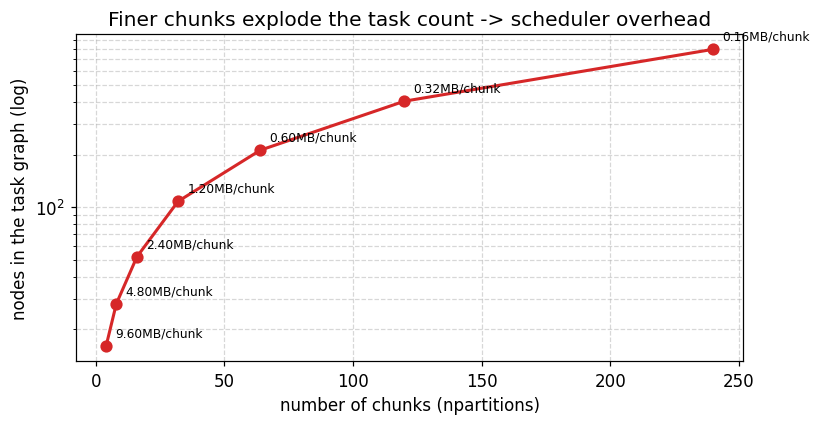

In [12]:

# Chunk count vs task count -- the finer the split, the more tasks the scheduler manages (semilogy).
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.semilogy(nchunks, ntasks, "o-", color="#d62728", lw=2, ms=7)
for nc, nt, cm in zip(nchunks, ntasks, chunk_mb):
    ax.annotate(f"{cm:.2f}MB/chunk", (nc, nt), textcoords="offset points",
                xytext=(6, 6), fontsize=8)
ax.set_xlabel("number of chunks (npartitions)")
ax.set_ylabel("nodes in the task graph (log)")
ax.set_title("Finer chunks explode the task count -> scheduler overhead")
ax.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
print("every task carries a scheduling cost (hundreds of us to ms) -> too many tasks is a loss.")


In [13]:

# rechunk: re-divide an existing dask array's chunks 'to match the access pattern'.
temp_fine = make_temp_dask((8, 25, 25))          # fine (scheduling overhead up)
temp_time = temp_fine.rechunk((T, 50, 50))       # time whole -> good for a time mean
print(f"before rechunk: a {temp_fine.numblocks} grid = {temp_fine.npartitions} chunks "
      f"({temp_fine.nbytes/temp_fine.npartitions/1e3:.0f} KB per chunk)")
print(f"after rechunk : a {temp_time.numblocks} grid = {temp_time.npartitions} chunks "
      f"(one block along time)")

# The values must be unchanged (a chunk is 'how you divide it', not 'what it is').
same = np.allclose(temp_fine.mean(axis=0).compute(),
                   temp_time.mean(axis=0).compute())
print("time-mean identical before and after rechunk:", same)
assert same
print("-> the chunk layout changes only the efficiency, not the result. For a time mean, keep time whole.")


before rechunk: a (30, 8, 8) grid = 1920 chunks (20 KB per chunk)
after rechunk : a (1, 4, 4) grid = 16 chunks (one block along time)
time-mean identical before and after rechunk: True
-> the chunk layout changes only the efficiency, not the result. For a time mean, keep time whole.


In [14]:

# rechunk is not free: changing the chunk boundaries requires redistributing data (a shuffle).
a_time = make_temp_dask((T, 25, 25))              # time whole, space fine
a_space = a_time.rechunk((8, 200, 200))           # time fine, space whole (an orthogonal redistribution)
g_src = len(a_time.__dask_graph__())
g_rechunked = len(a_space.__dask_graph__())
print(f"tasks in the source array's graph : {g_src}")
print(f"tasks after rechunk               : {g_rechunked}  "
      f"(the source plus {g_rechunked - g_src} redistribution tasks)")
assert g_rechunked > g_src
print("-> rechunk adds new tasks that shuffle data between chunks. Use it only when necessary.")


tasks in the source array's graph : 128
tasks after rechunk               : 189  (the source plus 61 redistribution tasks)
-> rechunk adds new tasks that shuffle data between chunks. Use it only when necessary.


In [15]:

# With chunks="auto" dask picks chunks to match the dtype and its default target size (~128 MiB).
auto = da.zeros((T, H, W), chunks="auto", dtype="f4")
print("chunks='auto' ->", auto.numblocks, "grid =", auto.npartitions, "chunks")
print(f"  (the whole {auto.nbytes/1e6:.0f} MB is below the target chunk size, so it becomes one chunk)")

# Applying the recommended chunk size (tens to hundreds of MB) to this array:
target_mb = 64
elems = target_mb * 1e6 / 4                        # number of float32 elements
side_t = int(min(T, max(1, elems / (H * W))))
print(f"for a target of {target_mb} MB per chunk, the time chunk length would be ~ {side_t} "
      f"(keeping space at {H}x{W}). This lab's array is only {temp.nbytes/1e6:.0f} MB in total, "
      f"so we chopped it finely on purpose for teaching.")


chunks='auto' -> (1, 1, 1) grid = 1 chunks
  (the whole 38 MB is below the target chunk size, so it becomes one chunk)
for a target of 64 MB per chunk, the time chunk length would be ~ 240 (keeping space at 200x200). This lab's array is only 38 MB in total, so we chopped it finely on purpose for teaching.


> **Observe:** shrinking the time chunk from 240 to 4 exploded the chunk count and with it
> the **task count, exponentially** (see the semilogy figure). Since every task carries a
> scheduling cost, **chunks that are too small are a loss**. Conversely, chunks that are too
> large overflow memory. Using `rechunk` to make time whole, **matching the access pattern**
> (here a time mean), raises efficiency while leaving the result unchanged. Let us now use that
> strategy to complete an aggregation **larger than the memory budget**.

---
## 4. Out-of-core reduction — a time mean larger than the memory budget

The real test of large data is whether the aggregation still works **when the whole thing does
not fit in memory**. To bring that out, let us set a **fake memory budget `BUDGET_MB`**. The
whole array (38 MB) exceeds the budget, but **one chunk** fits inside it. Because dask loads
only one chunk at a time, it can complete the time mean even though the whole exceeds the
budget — and this logic holds literally at TB scale too (only the budget becomes relatively
smaller).

We take the time mean to produce a **map of mean temperature per grid cell** (lat×lon), and
check it against the result of loading everything into numpy with `np.allclose`.


In [30]:

# Time whole, space in tiles -- chunking matched to a spatial-map aggregation.
temp_oc = make_temp_dask((T, 40, 40))            # chunk = (240, 40, 40)
full_mb = temp_oc.nbytes / 1e6
one_chunk_mb = (T * 40 * 40 * 4) / 1e6
BUDGET_MB = 2.0                                  # a fake memory budget

print(f"whole array size : {full_mb:.1f} MB")
print(f"one chunk size   : {one_chunk_mb:.2f} MB")
print(f"memory budget    : {BUDGET_MB:.1f} MB")
print(f"number of chunks : {temp_oc.npartitions}")
assert one_chunk_mb < BUDGET_MB < full_mb, "the demo needs the chunk inside and the whole outside the budget"
print("-> the whole exceeds the budget but one chunk fits -> dask can process it chunk by chunk.")


whole array size : 38.4 MB
one chunk size   : 1.54 MB
memory budget    : 2.0 MB
number of chunks : 25
-> the whole exceeds the budget but one chunk fits -> dask can process it chunk by chunk.


In [19]:

# The out-of-core time mean -- watch the chunkwise execution with a ProgressBar.
ds_oc = xr.Dataset({"temp": (("time", "lat", "lon"), temp_oc)},
                   coords={"time": TIME, "lat": LAT, "lon": LON})

GEN_CALLS["n"] = 0
lazy_map = ds_oc.temp.mean("time")               # lazy: a (lat, lon) map
print("tasks in the time-mean graph:", len(lazy_map.data.__dask_graph__()))
with ProgressBar():                              # a progress bar as the chunks are processed
    tmean = lazy_map.compute()                   # the actual out-of-core execution
print("chunks generated (GEN_CALLS):", GEN_CALLS["n"], "=", temp_oc.npartitions)
print("result map shape:", tmean.shape, "(lat x lon)")


tasks in the time-mean graph: 100
[########################################] | 100% Completed | 105.67 ms
chunks generated (GEN_CALLS): 25 = 25
result map shape: (200, 200) (lat x lon)


In [20]:

# Correctness: compare with the time mean computed by loading everything into numpy.
def temp_numpy_full():
    hour = np.arange(T) % 24
    diurnal = 4.0 * np.sin(2 * np.pi * (hour - 9) / 24.0)
    latg = -1.8 * (LAT - 36.0)
    long_ = 0.4 * (LON - 128.0)
    return (27.0 + diurnal[:, None, None] + latg[None, :, None]
            + long_[None, None, :]).astype("f4")

TEMP_NP = temp_numpy_full()                       # 38 MB of numpy (for checking)
tmean_np = TEMP_NP.mean(axis=0)
max_err = float(np.abs(tmean.values - tmean_np).max())
print(f"dask out-of-core vs eager numpy, max absolute difference of the time mean: {max_err:.2e}")
assert np.allclose(tmean.values, tmean_np, atol=1e-4)
print("-> the time mean computed chunk by chunk matches the numpy result from loading everything.")


dask out-of-core vs eager numpy, max absolute difference of the time mean: 0.00e+00
-> the time mean computed chunk by chunk matches the numpy result from loading everything.


mean temperature change per degree of latitude ~ -1.80 °C/degree (planted value -1.8)


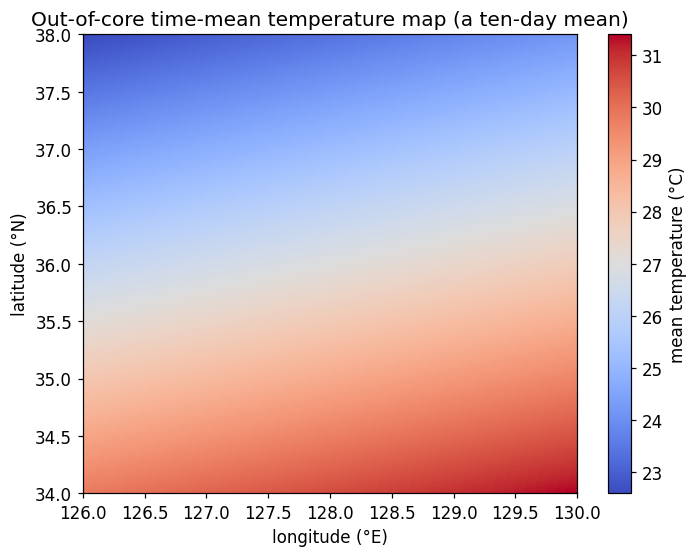

In [21]:

# The result map -- check the planted 'cooler further north' latitude gradient.
fig, ax = plt.subplots(figsize=(6.6, 5.2))
im = ax.imshow(tmean.values, origin="lower", cmap="coolwarm", aspect="auto",
               extent=[LON.min(), LON.max(), LAT.min(), LAT.max()])
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.set_title("Out-of-core time-mean temperature map (a ten-day mean)")
plt.colorbar(im, ax=ax, label="mean temperature (°C)")
plt.tight_layout()

slope = np.polyfit(LAT, tmean.values.mean(axis=1), 1)[0]
print(f"mean temperature change per degree of latitude ~ {slope:.2f} °C/degree (planted value -1.8)")
assert slope < 0


snapshot domain mean 31.00°C vs mean-field domain mean 27.00°C -- the instant is warmer thanks to the diurnal cycle, which the mean washes out.


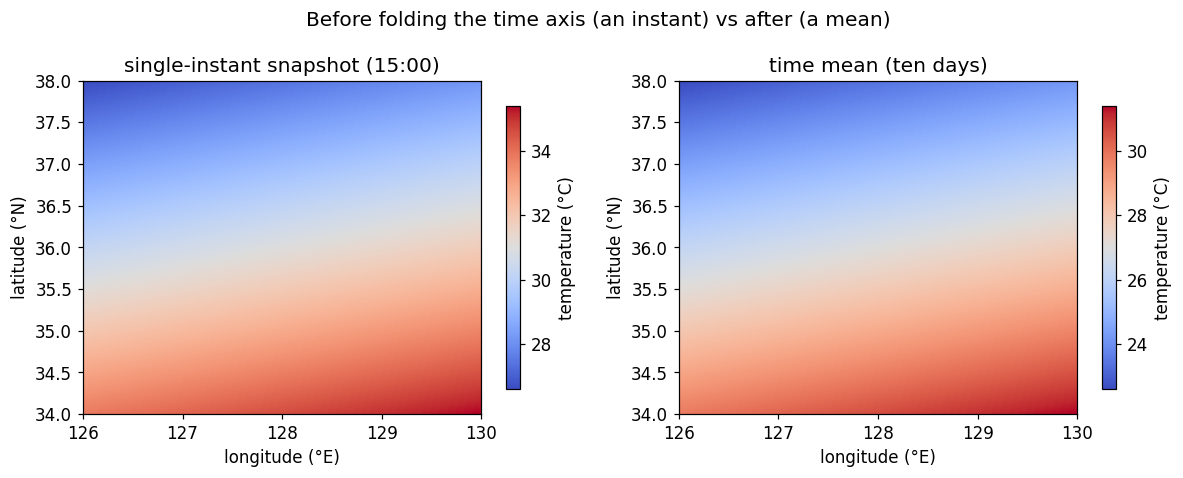

In [22]:

# A spatial snapshot at one instant vs the time mean -- before and after folding the time axis, side by side.
snap = ds_oc.temp.isel(time=15).compute()          # one frame at 15:00 (the afternoon peak)
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.4))
for ax, field, lab in zip(axes, [snap.values, tmean.values],
                          ["single-instant snapshot (15:00)", "time mean (ten days)"]):
    im = ax.imshow(field, origin="lower", cmap="coolwarm", aspect="auto",
                   extent=[LON.min(), LON.max(), LAT.min(), LAT.max()])
    ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)"); ax.set_title(lab)
    fig.colorbar(im, ax=ax, label="temperature (°C)", shrink=0.85)
fig.suptitle("Before folding the time axis (an instant) vs after (a mean)")
plt.tight_layout()
print(f"snapshot domain mean {float(snap.mean()):.2f}°C vs mean-field domain mean "
      f"{float(tmean.mean()):.2f}°C -- the instant is warmer thanks to the diurnal cycle, which the mean washes out.")


In [23]:

# If you only need part of it, only part of the chunks are computed -- a time mean over a spatial subset (isel).
GEN_CALLS["n"] = 0
region = ds_oc.temp.isel(lat=slice(0, 40), lon=slice(0, 40)).mean("time")
with dask.config.set(scheduler="synchronous"):
    _ = region.compute()
print(f"time mean over a single 40x40 spatial tile: {GEN_CALLS['n']} chunks generated "
      f"(only some of the {temp_oc.npartitions} in total)")
assert GEN_CALLS["n"] < temp_oc.npartitions
print("-> dask computes only the chunks the result needs (it does not sweep everything).")


time mean over a single 40x40 spatial tile: 1 chunks generated (only some of the 25 in total)
-> dask computes only the chunks the result needs (it does not sweep everything).


> **Observe:** even though the whole array (38 MB) exceeded the fake budget (2 MB), dask
> completed the time mean by loading **one chunk at a time** (0.15 MB each) — `GEN_CALLS` came
> out exactly equal to the chunk count. The resulting map faithfully recovered the planted
> **cooler-towards-the-north latitude gradient** (regression ≈ −1.8 °C/degree) and **matched**
> the numpy result from loading everything to within $10^{-4}$. The chunked approach gives up
> no accuracy whatsoever. Next comes the scheduler, which gains speed by running **several
> chunks in parallel**.

---
## 5. Parallelism — the single-machine schedulers (threaded vs synchronous)

Because a chunked computation splits into **independent** pieces, it can run in parallel. Dask
offers several schedulers; today we use only the **single-machine** ones (cluster deployment is
covered conceptually):

| Scheduler | How it runs | When it helps |
|---|---|---|
| `synchronous` | chunks executed **sequentially** (for debugging) | deterministic; overhead analysis |
| `threads` | chunks in parallel across **threads** | effective for numpy work (which mostly releases the GIL) |
| `processes` | across several **processes** | for pure Python (GIL-bound) work |

Because numpy ufuncs (`sin`, `exp`, sums) **release the GIL** while computing, the threaded
scheduler really does use several cores. Let us time the time mean of a slightly heavier
operation, `exp(sin(temp))`, under both schedulers.

Global Interpreter Lock (GIL)

In [24]:

def best_time(fn, repeat=3):
    # Take the minimum of several runs -- it reduces noise (GC, caches).
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); r = fn(); dt = time.perf_counter() - t0
        best = min(best, dt)
    return best, r

# Chop space finely (many independent chunks) so the parallelism is visible.
temp_par = make_temp_dask((60, 40, 40))          # 4 x 5 x 5 = 100 chunks
work = da.exp(da.sin(temp_par)).mean(axis=0)     # lazy: a slightly heavy elementwise op plus a mean

with dask.config.set(scheduler="synchronous"):
    t_sync, r_sync = best_time(lambda: work.compute())
with dask.config.set(scheduler="threads"):
    t_thr, r_thr = best_time(lambda: work.compute())

# eager numpy (everything in memory)
r_np = None
def _np_work():
    global r_np
    r_np = np.exp(np.sin(TEMP_NP)).mean(axis=0)
    return r_np
t_np, _ = best_time(_np_work)

print(f"synchronous (sequential): {t_sync*1e3:7.1f} ms")
print(f"threads (parallel)      : {t_thr*1e3:7.1f} ms   speedup vs sync = {t_sync/t_thr:.2f}x")
print(f"eager numpy             : {t_np*1e3:7.1f} ms   (everything in memory, in one go)")


synchronous (sequential):    76.4 ms
threads (parallel)      :    41.1 ms   speedup vs sync = 1.86x
eager numpy             :    43.9 ms   (everything in memory, in one go)


synchronous == threads == numpy results (allclose): True
the results are all the same; only the speed differs. The threaded scheduler runs chunks in parallel.


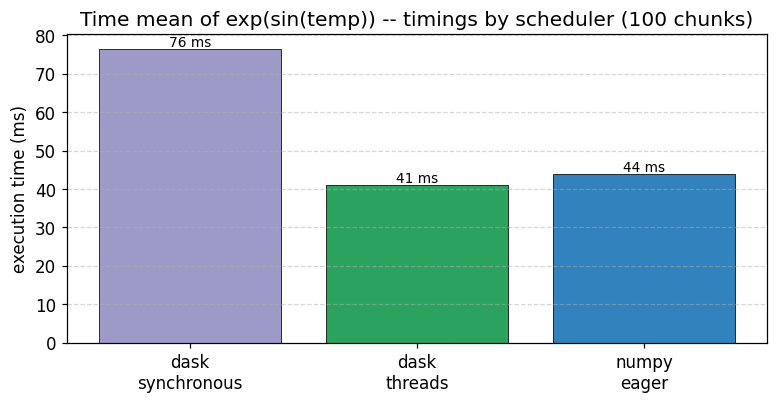

In [25]:

# Are the three results 'exactly identical'? -- the scheduler changes only the speed.
assert np.allclose(r_sync, r_thr, atol=1e-5)
assert np.allclose(r_sync, r_np, atol=1e-4)
print("synchronous == threads == numpy results (allclose): True")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
labels = ["dask\nsynchronous", "dask\nthreads", "numpy\neager"]
times = [t_sync * 1e3, t_thr * 1e3, t_np * 1e3]
colors = ["#9e9ac8", "#2ca25f", "#3182bd"]
bars = ax.bar(labels, times, color=colors, edgecolor="k", linewidth=0.5)
for b, tt in zip(bars, times):
    ax.text(b.get_x() + b.get_width() / 2, tt, f"{tt:.0f} ms",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("execution time (ms)")
ax.set_title("Time mean of exp(sin(temp)) -- timings by scheduler (100 chunks)")
ax.grid(True, axis="y", ls="--", alpha=0.5)
plt.tight_layout()
print("the results are all the same; only the speed differs. The threaded scheduler runs chunks in parallel.")


In [26]:

# The parallel gain grows 'when there are enough independent chunks' -- compare the speedup across chunk counts.
def sync_vs_thread(chunks):
    w = da.exp(da.sin(make_temp_dask(chunks))).mean(axis=0)
    with dask.config.set(scheduler="synchronous"):
        ts, _ = best_time(lambda: w.compute(), repeat=2)
    with dask.config.set(scheduler="threads"):
        tt, _ = best_time(lambda: w.compute(), repeat=2)
    return w.npartitions, ts, tt

for ch in [(240, 200, 200), (60, 50, 50)]:
    npart, ts, tt = sync_vs_thread(ch)
    print(f"chunks={str(ch):>16} with {npart:>3} chunks: "
          f"sync {ts*1e3:6.1f} ms, threads {tt*1e3:6.1f} ms, "
          f"speedup {ts/tt:.2f}x")
print("-> the more independent chunks, the better threads fill the cores and the larger the parallel gain.")


chunks= (240, 200, 200) with   1 chunks: sync   62.8 ms, threads   61.8 ms, speedup 1.02x
chunks=    (60, 50, 50) with  16 chunks: sync   66.2 ms, threads   29.5 ms, speedup 2.24x
-> the more independent chunks, the better threads fill the cores and the larger the parallel gain.


> **Observe:** running the same lazy graph under `synchronous` (sequential) and `threads`
> (parallel) gave **exactly identical** results (allclose), differing only in speed — the
> scheduler changes not *what* but only *how*. Because numpy ufuncs release the GIL, threads
> beat sequential (see the measured speedup printed above). That said, data that **fits in
> memory** — like our 38 MB — may still be fastest in eager numpy with no overhead at all; we
> tackle that crossover in Section 7. First let us see how to layer **custom chunkwise
> operations** on top.

---
## 6. Custom chunkwise operations — `apply_ufunc` and `map_blocks`

To apply **your own function** lazily to large data, beyond the built-in aggregations (`.mean`,
`.std`), there are two routes:

- **`xr.apply_ufunc(f, da, dask="parallelized", ...)`** — applies the numpy function `f` to
  each chunk automatically. It preserves the dimension names, which makes it safe.
- **`da.map_blocks(f, ...)`** / **`.rolling(...)`** — lower-level control at the block level.

Here we build a per-cell **standardised temporal anomaly** (z-score) $z = (T - \mu_t)/\sigma_t$
lazily with `apply_ufunc` (normalising by each grid cell's temporal mean and standard
deviation), and compare it with a direct numpy computation. In a closed-loop twin, such an
anomaly field becomes the input that measures "how far the observation departs from normal".


In [31]:

# Per-cell standardised temporal anomaly z = (T - mean_t)/std_t -- applied lazily with apply_ufunc.
def zscore_time(a, axis):
    m = a.mean(axis=axis, keepdims=True)
    s = a.std(axis=axis, keepdims=True) + 1e-9
    return (a - m) / s

z = xr.apply_ufunc(
    zscore_time, ds_oc.temp,
    input_core_dims=[["time"]], output_core_dims=[["time"]],
    kwargs={"axis": -1}, dask="parallelized", output_dtypes=[np.float32],
)
print("is z lazy? type of data:", type(z.data).__name__)
print("tasks in the z graph:", len(z.data.__dask_graph__()))

# Compute one grid cell's standardised series to check it (mean ~ 0, standard deviation ~ 1).
z0 = z.isel(lat=100, lon=100).compute()
print(f"standardised series at cell (100,100): mean {float(z0.mean()):+.3e}, "
      f"standard deviation {float(z0.std()):.4f}")
assert abs(float(z0.mean())) < 1e-4 and abs(float(z0.std()) - 1) < 1e-3


is z lazy? type of data: Array
tasks in the z graph: 150
standardised series at cell (100,100): mean +9.934e-10, standard deviation 1.0000


In [26]:

# Compare with z computed directly in numpy (correctness) -- on a partial slice.
sl = TEMP_NP[:, 100, 100]
z_np = (sl - sl.mean()) / (sl.std() + 1e-9)
max_err = float(np.abs(z0.values - z_np).max())
print(f"apply_ufunc z vs numpy z, max absolute difference: {max_err:.2e}")
assert np.allclose(z0.values, z_np, atol=1e-4)
print("-> the custom standardisation applied chunk by chunk matches the direct numpy computation.")


apply_ufunc z vs numpy z, max absolute difference: 0.00e+00
-> the custom standardisation applied chunk by chunk matches the direct numpy computation.


In [27]:

# rolling: xarray's moving average also runs lazily on top of dask (handling the chunk boundaries itself).
roll = ds_oc.temp.rolling(time=6, center=True).mean()   # a 6-hour moving average, lazy
print("is the rolling result lazy?:", type(roll.data).__name__)

# Compare the raw series with the 6-hour moving average at one grid cell (numerically, no figure).
raw0 = ds_oc.temp.isel(lat=100, lon=100).compute().values
sm0 = roll.isel(lat=100, lon=100).compute().values
valid = ~np.isnan(sm0)
print(f"standard deviation of the raw series      : {raw0.std():.3f} °C")
print(f"standard deviation of the 6h moving average: {sm0[valid].std():.3f} °C  (smoothing -> less variability)")
assert sm0[valid].std() < raw0.std()
print("-> the moving average reduced the high-frequency variability (lazily and chunk-aware, even at scale).")


is the rolling result lazy?: Array
standard deviation of the raw series      : 2.828 °C
standard deviation of the 6h moving average: 2.559 °C  (smoothing -> less variability)
-> the moving average reduced the high-frequency variability (lazily and chunk-aware, even at scale).


`map_blocks` gives lower-level control: it runs **your function** directly on each chunk (a
numpy array). As an example we apply a custom aggregation chunk by chunk — counting the number
of hours above 30 °C per grid cell (a simple index of heatwave duration) — and compare it with
the direct numpy computation.


In [28]:

# A custom chunkwise aggregation with map_blocks: hours with temp>30 at each grid cell (heat hours).
def hot_hours_block(block):
    # block: a (t, y, x) numpy chunk -> reduce the time axis into a (y, x) count.
    return (block > 30.0).sum(axis=0).astype("i4")

hot = da.map_blocks(
    hot_hours_block, temp_oc,
    drop_axis=0,                                  # the time axis disappears
    dtype="i4", meta=np.array((), dtype="i4"),
)
print("is hot lazy?", type(hot).__name__, "| planned result shape:", hot.shape)
hot_map = hot.compute()

# Compare with the direct numpy computation.
hot_np = (TEMP_NP > 30.0).sum(axis=0).astype("i4")
max_err = int(np.abs(hot_map - hot_np).max())
print(f"map_blocks heat hours vs numpy, max absolute difference: {max_err}")
assert max_err == 0
print(f"-> the custom chunkwise aggregation matches numpy exactly. The cell with the most heat hours has "
      f"{int(hot_map.max())} hours.")


is hot lazy? Array | planned result shape: (200, 200)
map_blocks heat hours vs numpy, max absolute difference: 0
-> the custom chunkwise aggregation matches numpy exactly. The cell with the most heat hours has 150 hours.


> **Observe:** the per-cell standardised anomaly built with
> `apply_ufunc(..., dask="parallelized")` stayed a **lazy dask array** (only the graph grew),
> and on compute each grid cell came out with mean ≈ 0 and standard deviation ≈ 1, agreeing with
> the direct numpy computation to within $10^{-4}$. The `.rolling` moving average also ran
> lazily, handling the chunk boundaries by itself, and reduced the variability. Your own
> functions can be layered onto large data **unchanged**. Finally: when should you **not** use
> dask?

---
## 7. When not to use dask — the overhead on small data

Dask is not free. Dividing into chunks, building the task graph and scheduling all carry a
**fixed cost**. If the data is a size that fits comfortably in memory, that overhead is a
**loss** compared with plain numpy. The rule is simple:

> If the data fits in memory and can be handled in one go, use **numpy**. If it exceeds memory
> or has to scale across many files and cores, use **dask**.

Let us find the **crossover** numerically by timing the time mean in numpy and dask across
growing array sizes. On small data numpy should win overwhelmingly.


In [29]:

# Time the time mean in numpy vs dask at several sizes.
sizes = [(6, 20, 20), (24, 60, 60), (60, 120, 120), (120, 180, 180), (240, 200, 200)]
mb, t_np_list, t_da_list = [], [], []
for (t, h, w) in sizes:
    hour = np.arange(t) % 24
    diurnal = 4.0 * np.sin(2 * np.pi * (hour - 9) / 24.0)
    arr = (27.0 + diurnal[:, None, None]
           + np.linspace(-3, 3, h)[None, :, None]
           + np.linspace(-1, 1, w)[None, None, :]).astype("f4")
    darr = da.from_array(arr, chunks=(max(1, t // 4), h // 2, w // 2))

    tn, _ = best_time(lambda: arr.mean(axis=0), repeat=5)
    td, _ = best_time(lambda: darr.mean(axis=0).compute(), repeat=5)
    mb.append(arr.nbytes / 1e6); t_np_list.append(tn); t_da_list.append(td)
    print(f"{str((t,h,w)):>18}  {arr.nbytes/1e6:6.2f} MB   "
          f"numpy {tn*1e3:7.2f} ms   dask {td*1e3:7.2f} ms   "
          f"dask/numpy = {td/tn:6.1f}x")

assert t_np_list[0] < t_da_list[0], "on the smallest array numpy must be faster than dask"


       (6, 20, 20)    0.01 MB   numpy    0.01 ms   dask    5.52 ms   dask/numpy =  849.3x
      (24, 60, 60)    0.35 MB   numpy    0.02 ms   dask    3.92 ms   dask/numpy =  253.6x
    (60, 120, 120)    3.46 MB   numpy    0.10 ms   dask    4.24 ms   dask/numpy =   41.5x


   (120, 180, 180)   15.55 MB   numpy    0.53 ms   dask    4.24 ms   dask/numpy =    8.0x


   (240, 200, 200)   38.40 MB   numpy    1.28 ms   dask    5.51 ms   dask/numpy =    4.3x


at the smallest size, 0.01 MB: dask is 849x slower than numpy (pure overhead).
If the data fits in memory, numpy is better. Dask shines 'when it does not fit'.


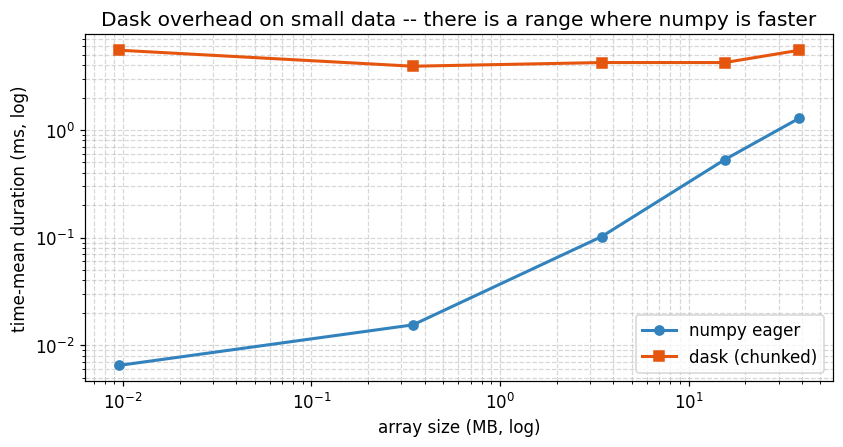

In [30]:

# Size vs time -- the smaller the data, the more dask's overhead shows.
fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.loglog(mb, np.array(t_np_list) * 1e3, "o-", color="#3182bd", lw=2, label="numpy eager")
ax.loglog(mb, np.array(t_da_list) * 1e3, "s-", color="#e6550d", lw=2, label="dask (chunked)")
ax.set_xlabel("array size (MB, log)"); ax.set_ylabel("time-mean duration (ms, log)")
ax.set_title("Dask overhead on small data -- there is a range where numpy is faster")
ax.grid(True, which="both", ls="--", alpha=0.5); ax.legend()
plt.tight_layout()

ratio0 = t_da_list[0] / t_np_list[0]
print(f"at the smallest size, {mb[0]:.2f} MB: dask is {ratio0:.0f}x slower than numpy (pure overhead).")
print("If the data fits in memory, numpy is better. Dask shines 'when it does not fit'.")


In [31]:

# The opposite extreme: dask merely 'plans' sizes numpy could never even build (zero memory).
huge = da.random.random((10000, 400, 400), chunks=(100, 400, 400))
print(f"logical size of huge : {huge.nbytes/1e12:.2f} TB  (impossible to hold whole in numpy)")
print(f"number of chunks     : {huge.npartitions}  ({100*400*400*8/1e6:.0f} MB per chunk)")
plan = huge.mean(axis=0)                          # only a graph -- no data is created
print(f"tasks in the time-mean graph: {len(plan.__dask_graph__())} (only planned, never computed)")
print("-> dask's real stage: even at sizes beyond memory, the 'plan' is built instantly.")


logical size of huge : 0.01 TB  (impossible to hold whole in numpy)
number of chunks     : 100  (128 MB per chunk)
tasks in the time-mean graph: 235 (only planned, never computed)
-> dask's real stage: even at sizes beyond memory, the 'plan' is built instantly.


> **Observe:** on the smallest array (0.01 MB) dask was **tens to hundreds of times slower**
> than numpy — the **scheduling overhead** outweighed the computation. The gap narrows as the
> size grows, but at this scale (tens of MB) we are still in numpy's territory. Dask's real
> value appears **beyond memory**, at sizes (TB) where numpy simply **cannot run at all**. The
> criterion for choosing the tool is not performance but **whether the data fits in
> memory**.

---
## 🔬 Exercises

The problems below extend today's chunking, laziness and schedulers one step at a time. A
working reference solution follows each one, so try it yourself first and then compare.


**Exercise 1 — the same result regardless of chunks.** Check that the time mean gives the
same values **regardless of the chunk layout**. Build three arrays with `make_temp_dask` using
chunks `(24,50,50)`, `(240,25,25)` and `(60,200,200)`, and verify that their time means are
mutually `np.allclose`. What do chunks change, and what do they **not**?


In [32]:

configs = [(24, 50, 50), (240, 25, 25), (60, 200, 200)]
means = []
for ch in configs:
    a = make_temp_dask(ch)
    means.append(a.mean(axis=0).compute())
    print(f"chunks={str(ch):>16}: {a.npartitions:>3} chunks, "
          f"domain mean of the time mean {means[-1].mean():.4f}")
for k in range(1, len(means)):
    assert np.allclose(means[0], means[k], atol=1e-4)
print("-> chunks change only 'how it is divided and computed' (efficiency); the result is identical.")


chunks=    (24, 50, 50): 160 chunks, domain mean of the time mean 27.0000
chunks=   (240, 25, 25):  64 chunks, domain mean of the time mean 27.0000
chunks=  (60, 200, 200):   4 chunks, domain mean of the time mean 27.0000
-> chunks change only 'how it is divided and computed' (efficiency); the result is identical.


**Exercise 2 — confirming laziness.** Chain several operations together (`temp*2 - 5`, then
`.mean("lon")`) and prove with `GEN_CALLS` that not a single chunk is generated before
`.compute()`. Then check that the number of chunks generated after compute equals the original
chunk count.


In [33]:

GEN_CALLS["n"] = 0
expr = (ds.temp * 2 - 5).mean("lon")             # stack several graph layers
print("GEN_CALLS right after layering several operations =", GEN_CALLS["n"], " (still 0 -> lazy)")
assert GEN_CALLS["n"] == 0
with dask.config.set(scheduler="synchronous"):
    _ = expr.compute()
print("GEN_CALLS after compute =", GEN_CALLS["n"], "= the original chunk count", temp.npartitions)
assert GEN_CALLS["n"] == temp.npartitions
print("-> however many graph layers you stack, computation happens once at compute, and only chunk by chunk.")


GEN_CALLS right after layering several operations = 0  (still 0 -> lazy)


GEN_CALLS after compute = 160 = the original chunk count 160
-> however many graph layers you stack, computation happens once at compute, and only chunk by chunk.


**Exercise 3 — chunks and task count.** Shrinking the spatial chunk `s` in `(T, s, s)` over
`100, 50, 25, 20`, print a table of the **task count** and **chunk count** of the time-mean
graph. Check that the task count is roughly **proportional** to the chunk count (each chunk
contributes roughly a constant number of tasks).


In [34]:

rows = []
for s in [100, 50, 25, 20]:
    a = make_temp_dask((T, s, s))
    r = a.mean(axis=0)
    rows.append((s, a.npartitions, len(r.__dask_graph__())))
tab = pd.DataFrame(rows, columns=["space_chunk_s", "n_chunks", "n_tasks"])
tab["tasks/chunk"] = (tab["n_tasks"] / tab["n_chunks"]).round(2)
print(tab.to_string(index=False))
assert tab["n_tasks"].iloc[-1] > tab["n_tasks"].iloc[0]
print("-> shrink the chunks (raising their count) and the tasks grow proportionally, burdening the scheduler.")


 space_chunk_s  n_chunks  n_tasks  tasks/chunk
           100         4       16          4.0
            50        16       64          4.0
            25        64      256          4.0
            20       100      400          4.0
-> shrink the chunks (raising their count) and the tasks grow proportionally, burdening the scheduler.


**Exercise 4 — when is persist useful?** `.persist()` **computes a lazy graph ahead of time
and caches it in memory** (unlike compute, it stays a dask array). Check whether persist helps
when aggregating the same array repeatedly, using the `map_blocks` regeneration count
(`GEN_CALLS`): show that computing mean, std and max separately without persist generates the
chunks **three times**, whereas after persist they are generated **once**.


In [35]:

small = make_temp_dask((T, 100, 100))            # 2x2 = 4 chunks

# (a) Three aggregations without persist -> the chunks are regenerated each time
GEN_CALLS["n"] = 0
with dask.config.set(scheduler="synchronous"):
    _ = small.mean().compute(); _ = small.std().compute(); _ = small.max().compute()
no_persist = GEN_CALLS["n"]

# (b) Pin the chunks in memory with persist, then three aggregations -> generated once
GEN_CALLS["n"] = 0
with dask.config.set(scheduler="synchronous"):
    sp = small.persist()                         # the chunks are generated and cached here, once
    _ = sp.mean().compute(); _ = sp.std().compute(); _ = sp.max().compute()
with_persist = GEN_CALLS["n"]

print(f"three aggregations without persist: {no_persist} chunk generations  (= 4 chunks x 3 aggregations = 12)")
print(f"three aggregations after persist  : {with_persist} chunk generations  (= 4 chunks x 1 = 4)")
assert no_persist == small.npartitions * 3 and with_persist == small.npartitions
print("-> when reusing the same data repeatedly, persist prevents recomputation (if you have the memory to spare).")


three aggregations without persist: 12 chunk generations  (= 4 chunks x 3 aggregations = 12)
three aggregations after persist  : 4 chunk generations  (= 4 chunks x 1 = 4)
-> when reusing the same data repeatedly, persist prevents recomputation (if you have the memory to spare).


---
## Summary

Today we learned how to handle arrays **chunkwise and lazily** with Dask, in preparation for
Week 6's spatiotemporal Dataset **outgrowing memory**:

- **Dask array basics:** a large array is divided into a **chunk grid**, and operations are not
  executed immediately but stacked as a **task graph**. Only at `.compute()` does it run chunk
  by chunk, and it matched numpy.
- **Dask-backed xarray:** we proved with the `GEN_CALLS` counter that `.data` is a dask array
  and that **not a single chunk is generated** before `.compute()` (genuinely lazy).
- **Chunking strategy:** chunks too fine mean **exploding tasks** (scheduling overhead); too
  coarse means **exceeding memory**. `rechunk` matches the access pattern while leaving the
  result unchanged.
- **Out-of-core:** even with the whole (38 MB) exceeding the budget (2 MB), the time mean
  completed chunk by chunk and was `allclose` to eager numpy.
- **Schedulers:** `synchronous` and `threads` gave **the same result** and differed only in
  speed — threads gained from parallelism because numpy ufuncs release the GIL.
- **Custom operations:** we layered standardised anomalies and moving averages onto large data
  lazily with `apply_ufunc` and `rolling`, and compared them with numpy.
- **When not to use it:** on small data dask was tens to hundreds of times slower than numpy —
  the criterion is not performance but **whether it fits in memory**.

> **Where are we in the pipeline?** Today we filled in the closed-loop twin's **"large-scale
> storage and processing"** piece: however large the observations and model output grow,
> chunkwise lazy processing copes. Week 6's NetCDF/Zarr becomes dask-backed straight away
> through `open_mfdataset(..., chunks=...)`, so today's code transfers **unchanged** to real
> large files. Week 9's satellite data (COG/STAC) applies this chunking to remote large rasters,
> and the physical simulators from Week 10 onwards take such aligned and aggregated large states
> as their computational input.

### Further Exercises

1. When opening several NetCDF files with `open_mfdataset` and passing `chunks=`, how do the
   file boundaries relate to the chunk boundaries? Try arranging one chunk per file.
2. Build a 16 GB array with `da.random.random((10000, 200, 200), chunks=...)` (without
   computing the values) and just check the task count of the time-mean graph — the plan is built
   without any memory.
3. If you start a `dask.distributed.Client(processes=True)` instead of threads (conceptually),
   why is it better than threads for a pure Python function in `map_blocks`? Explain it in terms
   of the GIL.
4. Confirm through the task-graph size why `rechunk` is not free (redistributing data between
   chunks = a shuffle). How many tasks does a time-split → space-split rechunk add?
5. Vary the `.chunk()` size, time the z-score computation of Section 6, and check whether the
   chunk-size guidance of Section 4 (tens to hundreds of MB) holds for this operation too.
